<center>

<h1 >Projet : Analyse de données e-commerce avec Python</h1>

<p><em>Mael Garnier - p2510998 - Polytech Lyon - 3A cycle informatique</em></p>
<p><em>octobre 2025</em></p>

</center>

**Note importante :**

Parmi les différentes fonctions présentées ci-dessous, beaucoup font des boucles volontairement peu optimisées, afin de respecter les attendus du projet (codage à la main, sans fonctions comme groupby(), ...

In [52]:

import sys

# Importation des bibliothèques nécessaires
import pandas as pd
import numpy as np
from datetime import datetime, timedelta
import random
import matplotlib.pyplot as plt

## Partie 1 : Génération d'un Dataset e-commerce

Nous allons générer l'équivalent d'une vente par jours de 2021 à 2024, pour chaque pays. Les données relatives aux produits (nom du produit, catégorie, prix, quantité) sont générées aléatoirement.

Ces données sont ensuites converties en DataFrame, puis écrites dans un fichier CSV.

In [53]:
dates = []
# Nombre de jours entre le 1er janvier 2021 et le 31 décembre 2024
totalDays = (datetime(2024, 12, 31) - datetime(2021, 1, 1)).days
# Pour chaque jour, on ajoute la date correspondante à la liste
for i in range (totalDays):
    dates.append(datetime(2021, 1, 1) + timedelta(days=i))

# Liste de pays
countries = ['France', 'Germany', 'USA', 'India', 'Japan']

# Liste de produits, par catégorie
categories = ['Electronics', 'Clothes', 'Sport']
products_by_cat = {
    'Electronics': ['Laptop', 'Smartphone', 'Headphones', 'Camera'],
    'Clothes': ['T-shirt', 'Dress', 'Shoes'],
    'Sport': ['Surf', 'Bike', 'Skate'],
}

# On génère un prix pour chaque produit
price_for_product = {}
for (cat, products) in products_by_cat.items():
    for product in products:
        price_for_product[product] = random.randint(50, 2000)

# On génère les données, en attribuant une vente par jour par pays
data = []
for country in countries:
    for day in dates:
        category = random.choice(categories) # Catégorie aléatoire
        product = random.choice(products_by_cat[category]) # Produit aléatoire dans la liste
        quantity = random.randint(1, 20) # Quantité aléatoire entre 1 et 20
        price = price_for_product[product] # On récupère le prix du produit, précédemment généré aléatoirement
        data.append({
            'Country': country,
            'Date': day,
            'Category': category,
            'Product': product,
            'Quantity': quantity,
            'Price': price,
            'Total': price * quantity,
        })

# Création du DataFrame pandas
temp_df = pd.DataFrame(data)

# Affichage des données
print('5 premières lignes :')
print(temp_df.head())
print('\n Nombre total de lignes : ', temp_df.shape)

# On exporte dans un fichier CSV
temp_df.to_csv('dataset.csv', index=False)


5 premières lignes :
  Country       Date     Category     Product  Quantity  Price  Total
0  France 2021-01-01        Sport        Surf        17    366   6222
1  France 2021-01-02  Electronics  Smartphone         9   1777  15993
2  France 2021-01-03        Sport       Skate         9   1564  14076
3  France 2021-01-04      Clothes     T-shirt         6    724   4344
4  France 2021-01-05        Sport        Bike        15   1850  27750

 Nombre total de lignes :  (7300, 7)


## Partie 2 : Analyse de données e-commerce

Dans cette partie, nous allons nous concentrer sur l'analyse et le traitement des données precedemment générées.

### Gestion de fichier
Commencons par charger notre fichier CSV (en vérifiant les erreurs) et filtrer les ventes.

In [54]:
# Charger un fichier CSV dans un DataFrame et gérer les erreurs potentielles
def load_csv(file_name):
    try :
        # Lecture du fichier avec panda
        df = pd.read_csv(file_name)
        df['Date'] = pd.to_datetime(df['Date'])
        return df
    except FileNotFoundError:
        # Affichage du message d'erreur si le fichier n'est pas trouvé
        print("Le fichier du dataset n'est pas trouvé, merci de verifier que celui-ci se trouve à la racine du projet.")
        # On arrête l'execution, pour éviter de futures erreurs
        sys.exit(1)
    except pd.errors.ParserError:
        # Affichage du message d'erreur si le fichier est mal formaté
        print("Le fichier semble mal formaté.")
        # On arrête l'execution, pour éviter de futures erreurs
        sys.exit(1)
    except TypeError:
        print("La date n'est pas au bon format.")
        sys.exit(1)

# Filtrer un DataFrame pour conserver tous les elements entre deux dates données
def filter_df_by_date(df, start_date, end_date):
    # Filtrage des ventes entre deux dates données
    date_mask = (df['Date'] > start_date) & (df['Date'] <= end_date)
    return df.loc[date_mask]

# Effectue le même filtrage que la fonction précédente, mais de manière manuelle (sans utiliser de masques)
def filter_df_by_date_manual(df, start_date, end_date):
    filtered_df = pd.DataFrame()
    for index, row in df.iterrows():
        if start_date < row['Date'] <= end_date:
            filtered_df = pd.concat([filtered_df, row.to_frame().T], ignore_index=True)
    return filtered_df

dataframe = load_csv('dataset.csv')
print("Dataframe chargé : ", dataframe.head())
dataframe = filter_df_by_date(dataframe, datetime(2021, 1, 2), datetime(2024, 12, 31))
print("Dataframe filtré par date : ", dataframe.head())
dataframe_manually_filtered = filter_df_by_date_manual(dataframe, datetime(2021, 1, 3), datetime(2024, 12, 31))
print("Dataframe filtré par date manuellement : ", dataframe_manually_filtered.head())

Dataframe chargé :    Country       Date     Category     Product  Quantity  Price  Total
0  France 2021-01-01        Sport        Surf        17    366   6222
1  France 2021-01-02  Electronics  Smartphone         9   1777  15993
2  France 2021-01-03        Sport       Skate         9   1564  14076
3  France 2021-01-04      Clothes     T-shirt         6    724   4344
4  France 2021-01-05        Sport        Bike        15   1850  27750
Dataframe filtré par date :    Country       Date Category  Product  Quantity  Price  Total
2  France 2021-01-03    Sport    Skate         9   1564  14076
3  France 2021-01-04  Clothes  T-shirt         6    724   4344
4  France 2021-01-05    Sport     Bike        15   1850  27750
5  France 2021-01-06  Clothes  T-shirt         7    724   5068
6  France 2021-01-07    Sport     Bike        13   1850  24050
Dataframe filtré par date manuellement :    Country                 Date     Category  Product Quantity Price  Total
0  France  2021-01-04 00:00:00      

### Analyse de données

Nous allons calculer : le chiffre d'affaires total, moyen, maximal, minimal sur la periode donnée.

Nous allons egalement identifier le top 3 des produits les plus vendus et le top 3 des pays les plus rentables sur la periode donnée.

Pour finir, nous allons detecter les potentielles anomalies de ventes (jours sans vente, pics de vente inhabituels).

In [55]:
dataframe = load_csv('dataset.csv')
dataframe = filter_df_by_date(dataframe, datetime(2024, 1, 1), datetime(2024, 6, 30))
ca_total = dataframe['Total'].sum()
ca_moyen = dataframe['Total'].mean()
ca_max = dataframe['Total'].max()
ca_min = dataframe['Total'].min()

print("Chiffre d'affaire total de 2022 à 2023 : ", ca_total)
print("Chiffre d'affaire moyen de 2022 à 2023 : ", ca_moyen)
print("Chiffre d'affaire maximal de 2022 à 2023 : ", ca_max)
print("Chiffre d'affaire minimal de 2022 à 2023 : ", ca_min)

def get_top_3_product_by_sales(df):
    # On calcul le total de ventes par produit
    top_products = []

    for index, row in df.iterrows():
        # Si le produit n'est pas encore dans la liste, on l'ajoute
        if not any(prod['Name'] == row['Product'] for prod in top_products):
            top_products.append({
                'Name': row['Product'],
                'Category': row['Category'],
                'Sales': row['Quantity'],
            })
        else:
            for product in top_products:
                if product['Name'] == row['Product']:
                    product['Sales'] += row['Quantity']
                    break

    # On trie les produits en fonction du nombre de ventes
    for i in range(1, len(top_products)):
        cle = top_products[i]
        j = i-1
        while j>=0 and top_products[j]['Sales'] > cle['Sales']:
            top_products[j+1] = top_products[j] # decalage
            j = j-1
        top_products[j+1] = cle
    # On retourne seulement les trois derniers produits, qui sont les plus haut en sales
    return top_products[len(top_products)-3:]

top_3_products = get_top_3_product_by_sales(dataframe)

print("Top 3 des produits les plus vendus : ", [prod['Name'] for prod in top_3_products])

def get_top_3_countries(df):
    # On calcul le total de ventes par produit
    top_countries = []

    for index, row in df.iterrows():
        # Si le produit n'est pas encore dans la liste, on l'ajoute
        if not any(country['Country'] == row['Country'] for country in top_countries):
            top_countries.append({
                'Country': row['Country'],
                'CA': row['Total'],
            })
        else:
            for country in top_countries:
                if country['Country'] == row['Country']:
                    country['CA'] += row['Total']
                    break

    # On trie les pays en fonction du CA
    for i in range(1, len(top_countries)):
        cle = top_countries[i]
        j = i-1
        while j>=0 and top_countries[j]['CA'] > cle['CA']:
            top_countries[j+1] = top_countries[j] # decalage
            j = j-1
        top_countries[j+1] = cle
    # On retourne seulement les trois derniers pays
    return top_countries[len(top_countries)-3:]

top_3_countries = get_top_3_countries(dataframe)

print("Top 3 des pays les plus rentables : ", [coun['Country'] for coun in top_3_countries])

def detect_days_without_sales(df):
    # Liste de toutes les dates devant figurer dans le DataFrame
    dates_list = pd.date_range(start=df['Date'].min(), end=df['Date'].max())
    days_without_sales = []
    # Pour chaque date, si elle n'est pas présente dans le df, on l'ajoute a la liste
    for date in dates_list:
        if date not in df['Date'].values:
            days_without_sales.append(date)

    return days_without_sales

days_without_sales = detect_days_without_sales(dataframe)
print("Jours sans ventes : ", days_without_sales)

# retourne le df sans les valeurs aberrantes
def get_df_without_outlier(df, column):
    # On calcul l'ecart interquartile
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    # On definit les bornes
    lower_limit = Q1 - 1 * IQR # On devrait prendre 1.5*IQR, mais on reduit la marge afin d'avoir plus de chance d'obtenir des valeurs aberrantes, pour la demo
    upper_limit = Q3 + 1 * IQR

    return df[(df[column] >= lower_limit) & (df[column] <= upper_limit)]

# retourne les valeurs aberrantes
def get_outlier(df, column):
    # On calcul l'ecart interquartile
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    # On definit les bornes
    lower_limit = Q1 - 1 * IQR # On devrait prendre 1.5*IQR, mais on reduit la marge afin d'avoir plus de chance d'obtenir des valeurs aberrantes, pour la demo
    upper_limit = Q3 + 1 * IQR

    return df[(df[column] < lower_limit) | (df[column] > upper_limit)]

df_without_outliers_total = get_outlier(dataframe, 'Total')
print("Nombre de valeur aberrantes trouvées : ", len(df_without_outliers_total))

Chiffre d'affaire total de 2022 à 2023 :  9579317
Chiffre d'affaire moyen de 2022 à 2023 :  10584.880662983425
Chiffre d'affaire maximal de 2022 à 2023 :  37000
Chiffre d'affaire minimal de 2022 à 2023 :  366
Top 3 des produits les plus vendus :  ['Surf', 'Shoes', 'Dress']
Top 3 des pays les plus rentables :  ['Japan', 'France', 'Germany']
Jours sans ventes :  []
Nombre de valeur aberrantes trouvées :  43


### Visualisation des resultats

Nous allons maintenant visualiser les données que nous avons traité à l'aide de graphiques

#### Ventes par jours

Nous allons visualiser les ventes de T-shirt par jours (sur la periode que nous avons determinée à l'avance, c'est a dire les six premiers mois de l'année 2024).
Les valeurs aberrantes sont marquées par une barre rouge.

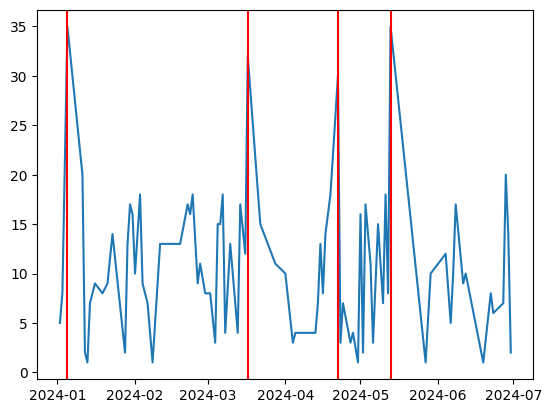

In [56]:
# Etudions les ventes quotidiennes de laptops

# On créé un dataframe avec les produits tshirt groupés par jour
mask_tshirt = (dataframe['Product'] == 'T-shirt')
tshirt_dataframe = dataframe[mask_tshirt].copy()
# Selon l'ennoncé, l'utilisation de fonction comme groupby ne semble plus interdite pour cette partie
tshirt_per_day_df = tshirt_dataframe.groupby('Date').sum()
plt.plot(tshirt_per_day_df['Quantity'].index, tshirt_per_day_df['Quantity'].values)

#On affiche des barres rouges pour les valeurs aberrantes
tshirt_per_day_without_outliers_df = get_outlier(tshirt_per_day_df, 'Quantity')
# On parcours notre dataframe avec toutes les valeurs, et si l'une des valeurs n'est pas presente dans le dataframe sans valeurs aberrantes, on l'affiche
for index, row in tshirt_per_day_without_outliers_df.iterrows():
    plt.axvline(x=index, color='red')


#### Ventes par mois pour chaque pays

Etudions maintenant la distribution des ventes pour chaque mois par pays. Chaque graphique montre, pour chaque plage de chiffre d'affaire, combien de mois appartiennent a cette plage. La periode concernée est la meme que precedemment

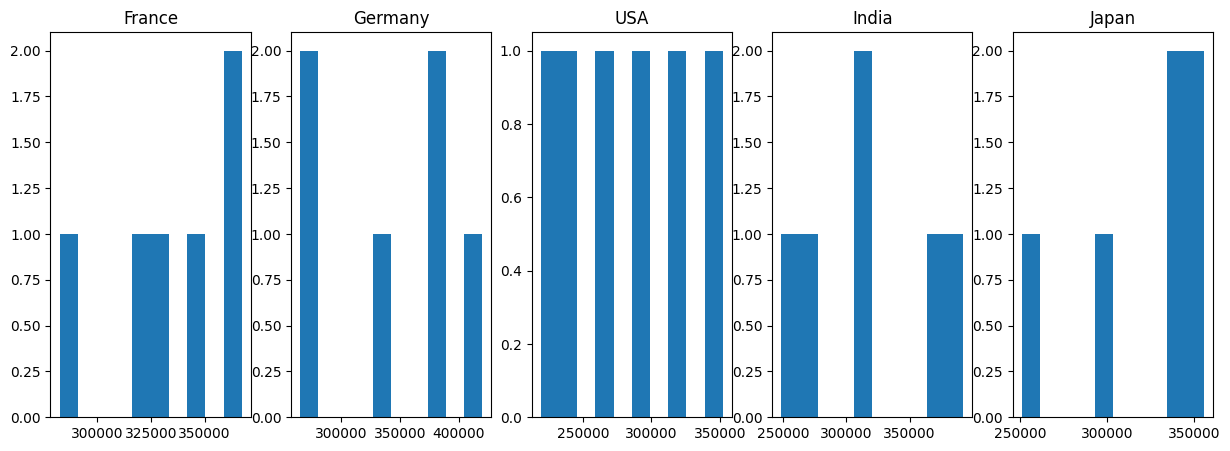

In [57]:
# On rappel les differents pays
countries = ['France', 'Germany', 'USA', 'India', 'Japan']

# Le graphique principal
fig, ax = plt.subplots(1, len(countries), figsize=(15, 5))

# On rajoute un sous graphique par pays
for i, country in enumerate(countries):

    # On filtre pour avoir que le pays
    dataframe_country = dataframe[dataframe['Country'] == country]

    # On regroupe par mois
    data_frame_country_per_month = dataframe_country.copy()
    data_frame_country_per_month['Date'] = data_frame_country_per_month['Date'].dt.to_period('M')
    data_frame_country_total_per_month = data_frame_country_per_month.groupby('Date')['Total'].sum()

    # On trace l'histogramme
    ax[i].hist(data_frame_country_total_per_month.values)
    ax[i].set_title(country)